# 04 · Fixed-split evaluation of the representative GraphSAGE model

> Part of the spatial-niche-gbm walk-through. The project is a **benchmark**: it tests whether spatial graph neural networks improve supervised niche prediction in glioblastoma Visium data over matched graph-free models (they do not). See `docs/00_overview_and_roadmap.md`. Notebooks read `data/` (see `docs/WORKFLOW.md`, step A) and the tracked `results/`; none of them trains a model.

This reproduces the per-class results of the seed-7 GraphSAGE model on the primary split (Figures 1–3 and
Supplementary Table S7) by running inference with the published checkpoint. Its role in the paper is
descriptive: it shows what the model does and how it fails. The model comparison itself is in notebook 06.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()          # run from notebooks/
PRE = REPO / "data" / "preprocessed"
RES = REPO / "results"
NICHES = ["immune_cold", "immune_hot", "normal", "necrotic"]
COLORS = {"immune_cold": "#D55E00", "immune_hot": "#0072B2", "normal": "#009E73",
          "necrotic": "#CC79A7", "exclude": "#DDDDDD"}
pd.set_option("display.precision", 3)
import torch, yaml
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from spatial_niche_gbm.models.multitask import MultiTaskGNN
from spatial_niche_gbm.training.evaluate import (NICHE_CLASSES, predict_graphs, tune_thresholds,
                                             apply_thresholds, classification_metrics, mes_metrics)

In [2]:
cfg = yaml.safe_load(open(REPO / "configs" / "default.yaml"))
splits = json.load(open(REPO / "configs" / "splits.json"))
graphs = torch.load(PRE / "graphs.pt", weights_only=False)
val = [g for g in graphs if g.patient in splits["val"]]
test = [g for g in graphs if g.patient in splits["test"]]
model = MultiTaskGNN(in_dim=3000, hidden_dims=cfg["model"]["hidden_dims"], dropout=cfg["model"]["dropout"])
model.load_state_dict(torch.load(RES / "models" / "best_model.pt", weights_only=False)["model_state"])
model.eval()
print(f"validation: {len(val)} sections {splits['val']} | test: {len(test)} sections {splits['test']}")

validation: 4 sections ['SNU24', 'SNU51'] | test: 5 sections ['SNU16', 'SNU33', 'SNU34']


## 1. Thresholds are tuned on validation patients only

For every model in the paper, a per-class threshold t_c is tuned on the validation patients. Test spots
are assigned to argmax p_c / t_c using those thresholds unchanged.

In [3]:
vp = predict_graphs(model, val)
vy = torch.cat([p["niche_y"] for p in vp]).numpy(); m = vy >= 0
vprob = torch.softmax(torch.cat([p["niche_logits"] for p in vp]), 1).numpy()[m]
thr = tune_thresholds(vy[m], vprob)
print("validation immune-hot spots:", int((vy == 1).sum()))
pd.Series(np.round(thr, 3), index=NICHE_CLASSES, name="threshold")

validation immune-hot spots: 15


immune_cold    0.300
immune_hot     0.050
normal         0.725
necrotic       0.150
Name: threshold, dtype: float32

The immune-hot threshold (0.05) is tuned on only 15 validation spots, so the model's immune-hot
performance on this split rests heavily on that tuning.

## 2. Held-out test patients

In [4]:
tp = predict_graphs(model, test)
met = classification_metrics(tp, thr=thr); met.update(mes_metrics(tp))
ty = torch.cat([p["niche_y"] for p in tp]).numpy()
prev = {c: float((ty[ty >= 0] == i).mean()) for i, c in enumerate(NICHE_CLASSES)}
print(f"macro-F1 {met['macro_f1']:.3f} | weighted-F1 {met['weighted_f1']:.3f} | accuracy {met['accuracy']:.3f} | MES AUROC {met['mes_auroc']:.3f}")
pd.DataFrame({c: {"F1": met[f"f1_{c}"], "AUROC": met[f"auroc_{c}"], "AUPRC": met[f"auprc_{c}"],
                  "AUPRC at chance": prev[c]} for c in NICHE_CLASSES}).T.round(3)

macro-F1 0.504 | weighted-F1 0.698 | accuracy 0.740 | MES AUROC 0.746


,F1,AUROC,AUPRC,AUPRC at chance
immune_cold,0.836,0.821,0.913,0.679
immune_hot,0.473,0.979,0.573,0.011
normal,0.241,0.729,0.266,0.089
necrotic,0.466,0.956,0.862,0.221


This matches Supplementary Table S7: macro-F1 0.504, accuracy 0.740. The high immune-hot AUROC
(0.98) **overstates** how well this class is resolved. Immune-hot is 1.1% of test spots, and its AUPRC
(0.57) should be read against a chance level of about 0.01. Normal is the weakest class (AUPRC 0.27 against
0.09).

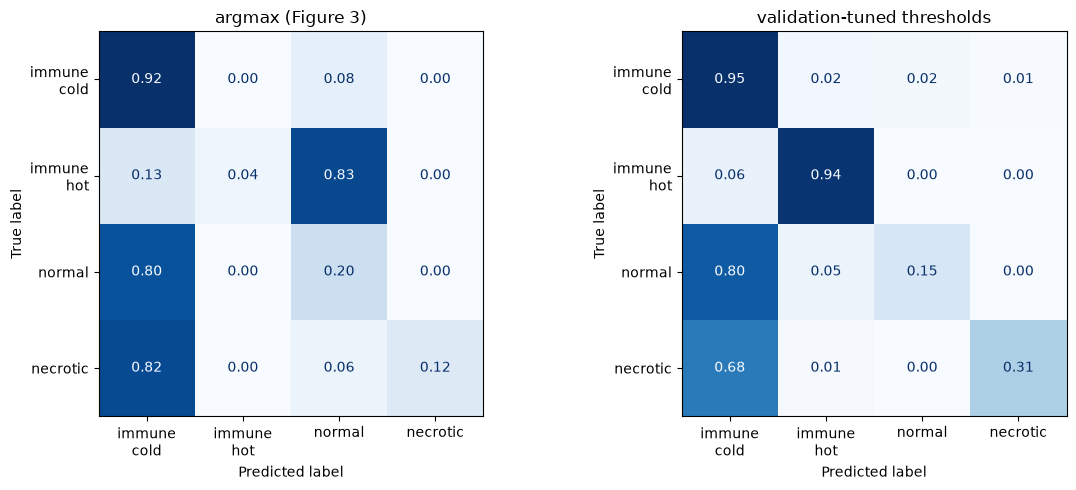

In [5]:
tprob = torch.softmax(torch.cat([p["niche_logits"] for p in tp]), 1).numpy()[ty >= 0]
yl = ty[ty >= 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in [(axes[0], tprob.argmax(1), "argmax (Figure 3)"), (axes[1], apply_thresholds(tprob, thr), "validation-tuned thresholds")]:
    cm = confusion_matrix(yl, pred, labels=range(4), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=[c.replace("_", "\n") for c in NICHE_CLASSES]).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

Under argmax, most normal and necrotic spots are assigned to immune-cold, and most immune-hot spots to
normal. Tuned thresholds recover immune-hot but leave normal-to-immune-cold confusion as the main error.

## 3. Spatial maps

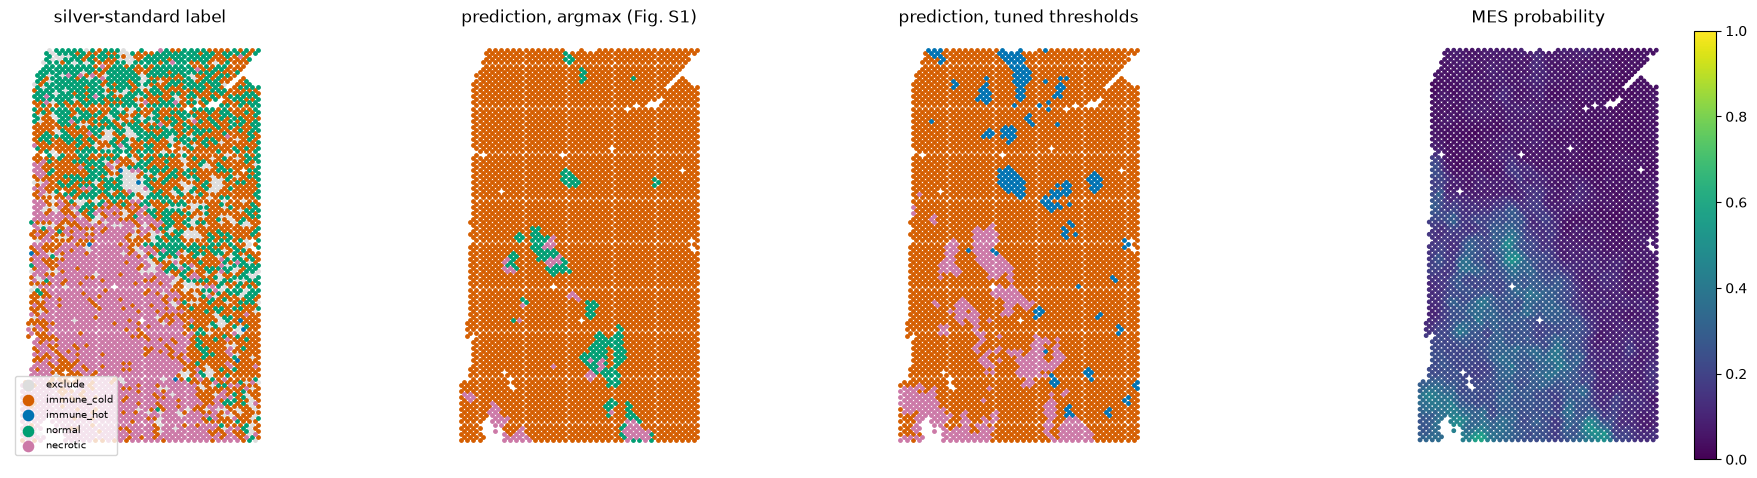

In [6]:
g = next(x for x in test if x.section == "SNU16A")
xy = np.load(PRE / "SNU16A_coords.npy")
with torch.no_grad():
    o = model(g.x, g.edge_index)
p = torch.softmax(o["niche_logits"], 1).numpy()
true = np.array([NICHE_CLASSES[v] if v >= 0 else "exclude" for v in g.niche_y.numpy()])
panels = [("silver-standard label", true), ("prediction, argmax (Fig. S1)", np.array(NICHE_CLASSES)[p.argmax(1)]),
          ("prediction, tuned thresholds", np.array(NICHE_CLASSES)[apply_thresholds(p, thr)])]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))
for ax, (title, lab) in zip(axes, panels):
    for c in ["exclude", *NICHE_CLASSES]:
        k = lab == c
        if k.any(): ax.scatter(xy[k, 1], -xy[k, 0], s=6, c=COLORS[c], label=c)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
axes[0].legend(markerscale=3, fontsize=7, loc="lower left")
sc = axes[3].scatter(xy[:, 1], -xy[:, 0], s=6, c=o["mes_prob"].numpy(), cmap="viridis", vmin=0, vmax=1)
axes[3].set_title("MES probability"); axes[3].set_aspect("equal"); axes[3].axis("off"); plt.colorbar(sc, ax=axes[3], fraction=0.046)
plt.tight_layout(); plt.show()

The maps show the failure modes the paper describes, not a faithful reconstruction. Under argmax, the
model assigns most of SNU16A to immune-cold and misses the large necrotic region in the lower left. Its
predictions are smoother and more contiguous than the labels. The MES probability is highest over the
silver-standard necrotic region, consistent with reports linking MES programs to perinecrotic tissue, even
though the classifier does not recover that region. Leave-one-patient-out maps with per-fold tuning are in
Figure 7 of the manuscript.